In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Midterm Practice Exam

## Question 1



In [2]:
# Response
def gradient_descent_update(x):
    eta = 0.1
    gradient = 4 * x + 4
    result = x - eta * gradient
    return result

print(gradient_descent_update(2))

0.7999999999999998


## Question 2



In [7]:
# Response
import numpy as np

X = np.array([1, 3, 5, 4, 2])
theta_0 = 0
theta_1 = 1
y = np.array([2, 4, 5, 3, 3])

y_pred = theta_0 + theta_1 * X
error = y_pred - y
mse = np.mean(error**2)
print(mse)

0.8


## Question 3



In [15]:
# Response
import numpy as np

X = np.array([[1, 5, 1, 2]])
theta = np.array([2, -1, 4, 8])
y = np.array([6])
eta = 0.01
m = len(y)

y_pred = X @ theta
error = y_pred - y
gradient = (X.T @ error)/m

new_theta = theta - eta * gradient
print(new_theta)


[ 1.89 -1.55  3.89  7.78]


## Question 4



In [17]:
# Response
import numpy as np

w = np.array([2,-1,4,8], dtype=float) #w[ 0] = bias
X = np.array([[1,5,1,2]], dtype=float)
y = np.array([10])
eta = 0.1
alpha = 0.3
m = len(y)

y_pred = X @ w
error = y_pred - y
gradient = (X.T @ error)/m

penalty = np.zeros_like(w)
print(penalty)
penalty[1:] = alpha * np.sign(w[1:])
print(penalty[1:])

loss = gradient + penalty

w_new = w - eta * loss
list(np.round(w_new,2))

[0. 0. 0. 0.]
[-0.3  0.3  0.3]


[np.float64(1.3), np.float64(-4.47), np.float64(3.27), np.float64(6.57)]

## Question 5



In [21]:
import numpy as np
from sklearn.naive_bayes import MultinomialNB

# Vocabulary order:
# Chinese, Beijing, Shanghai, Macao, Tokyo, Japan

# Step 1: Training data
vocabulary = ['Chinese', 'Beijing', 'Shanghai', 'Macao', 'Tokyo', 'Japan']
V = len(vocabulary)

X_train = np.array([
    [2,1,0,0,0,0],
    [2,0,1,0,0,0],
    [1,0,0,1,0,0],
    [1,0,0,0,1,1]
])

y_train = np.array([1,1,1,0]) #t_train

display(pd.DataFrame(
    X_train, 
    index = ['d1','d2','d3','d4'], 
    columns = vocabulary
))

# Step 2: Test document
X_test = np.array([[3,0,0,0,1,1]])  #TEST DOCUMENT

# Step 3: Class priors
prior_1 = np.mean(y_train == 1)
prior_0 = np.mean(y_train == 0)

# Step 4: Split training data by class
class_1 = X_train[y_train == 1]
class_0 = X_train[y_train == 0]

# Step 5: Calculate word probabilities
# Using Laplace (add-one) smoothing
word_prob_1 = (class_1.sum(axis=0) + 1) / (class_1.sum() + V)
word_prob_0 = (class_0.sum(axis=0) + 1) / (class_0.sum() + V)

# Step 6: Calculate unnormalized posterior scores
score_1 = prior_1 * np.prod(word_prob_1 ** X_test)
score_0 = prior_0 * np.prod(word_prob_0 ** X_test)

# Step 7: Normalize posterior probabilities
posterior_1 = score_1 / (score_1 + score_0)
posterior_0 = score_0 / (score_1 + score_0)

print(f"P(Class=1 | D5): {posterior_1:.4f}")
print(f"P(Class=0 | D5): {posterior_0:.4f}")
print(f"Exam answer: {posterior_1 * 100:.0f}")

,Chinese,Beijing,Shanghai,Macao,Tokyo,Japan
d1,2,1,0,0,0,0
d2,2,0,1,0,0,0
d3,1,0,0,1,0,0
d4,1,0,0,0,1,1


P(Class=1 | D5): 0.6898
P(Class=0 | D5): 0.3102
Exam answer: 69


## Question 6


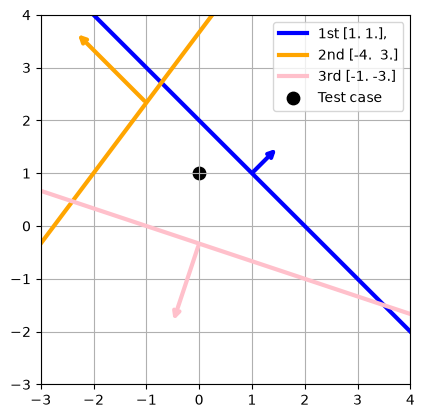

[np.int64(-1), np.int64(-8), np.int64(-4)]


In [25]:
import numpy as np
import matplotlib.pyplot as plt

W = np.array([[-2., 1., 1],  [-11,-4., 3. ], [-1, -1., -3.]])
cs =["b", "orange", "pink"] #colors
x = np.arange(-3, 5)
plt.plot(x, (2. - 1. * x) / 1., c = cs[0], label= f"1st {W[0,1:]},", lw=3)
plt.plot(x, (11. + 4. * x) / 3., c = cs[1], label=f"2nd {W[1,1:]}", lw=3)
plt.plot(x, (-1. - 1. * x) / 3., c = cs[2], label=f"3rd {W[2,1:]}", lw=3)
plt.gca().set_aspect('equal', adjustable='box') 
plt.scatter([0], [1], c="k", s=80, label = "Test case")  #plot the test case

#plot vectors that are normal each hyperplane
i=0; plt.annotate("", xy=W[i,1:]+[0.5, 0.5], c = cs[i], xytext=W[i,1:], arrowprops=dict(fc=cs[i], ec=cs[i],lw=3, arrowstyle="->"))
i=1; plt.annotate("", xy=[-1*4/3. + -1, 1*4/3+7./3.], c = cs[i], xytext=(-1, 7./3.), arrowprops=dict(fc=cs[i], ec=cs[i],lw=3, arrowstyle="->"))
i=2; plt.annotate("", xy=[-0.5, (-0.5/0.333)-0.333], c = cs[i], xytext=[-0.0, -0.333], arrowprops=dict(fc=cs[i], ec=cs[i],lw=3, arrowstyle="->"))
plt.xlim([-3, 4])
plt.ylim([-3, 4])
plt.grid()
plt.legend()
plt.show()
# 3 hyperplanes
W = np.array([[1,1],
              [-4,3],
              [-1,-3]])
b = np.array([-2,-11,-1])
#test case
x = np.array([[0,1]])
# Response
pDist = np.dot(x, W.T) + b
print(list((pDist).reshape(-1).astype('int')))

## Question 7



In [26]:
# Response
w = np.array([
    [1, 1],
    [-4, 3],
    [-1, -3]
])
b = np.array([-2, -11, -1])
x = np.array([0, 1])

# Calculate perpendicular distances
scores = np.dot(x, w.T) + b
perpdist = np.exp(scores - np.max(scores))

class_prob = perpdist / np.sum(perpdist)
print(list(np.round(class_prob,3).reshape(-1)))

[np.float64(0.952), np.float64(0.001), np.float64(0.047)]


## Question 8



In [30]:
X = np.array([
    [1,2,0], 
    [1,2,3], 
    [1,4,3], 
    [1,0,1]
])
w = np.array([1,2,-1])
y = np.array([0, 1, 1,0])

# predicted probabilities
z = X @ w
p_hat = 1 / (1 + np.exp(-z)) 

CXE_loss = -np.sum((y * np.log(p_hat)) + ((1-y) * np.log(1-p_hat)))
print(f"{CXE_loss:5.2f}")

 5.83


## Question 9



In [33]:
# Starter code
W = np.array([-5, 4])
X = np.array([[1, 1]])
y = np.array([1])
m = len(y)

alpha = 0.01
lamb  = 0.1

y_pred = X @ W
error = y_pred - y
gradient = (X.T @ error) / m

penalty = np.zeros_like(W)
penalty[1:] = lamb * W[1:]

W_new = W - alpha * (gradient + penalty)
print(W_new)

[-4.98  4.02]


## Question 10



In [ ]:
# Starter code
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)
# pipeline starts here
params = {'lr__C': [1.0, 10.0, 100.0] }

lr_pipeline = Pipeline([
    ('scaler', StandardScaler()), 
    ('lr', LogisticRegression())
]) # use solver='liblinear', multi_class='ovr'

gs = GridSearchCV(lr_pipeline, param_grid=__________, cv=___, refit=True)
gs.fit(X_train, y_train)
y_preds = gs.predict(X_test)

# Test score
score = ________(y_test, y_preds)
print(score)

## Question 13
Please complete this question in Canvas.


## Question 14

### Grid Search: HyperParameter tuning on steroids for Classification Tasks

Machine learning models are parameterized so that their behavior can be tuned for a given problem. Models can have many parameters and finding the best combination of parameters can be treated as a search problem. In this section you will discover how to tune the parameters of machine learning algorithms in Python using the scikit-learn.

Grid search is an approach to parameter tuning that will methodically build and evaluate a model for each combination of algorithm parameters specified in a grid. You can perform a grid search using the GridSearchCV class1. 
In this section we will focus on setting up a pipeline for classifiction, though it can be adapted to almost any machine learning problem.

### Pima Indian Grid search to find the Ridge LR
The code below explores different alphas (where alpha corresponds to weight given to the regularization term in the Ridge objective function) for the Ridge Logistic Regression algorithm. For more information on RidgeClassifier see https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeClassifier.html .

This code performs  a one-dimensional grid search to deterime alpha for the Pima-Indian Diabetes binary classifiction problem.

In [34]:
# Grid Search for Algorithm Tuning
import numpy as np
from pandas import read_csv
from sklearn.linear_model import RidgeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

#Note the data file is available in the same folder where the exam is located
filename = 'pima-indians-diabetes.data.csv'
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
dataframe = read_csv(filename, names=names)
array = dataframe.values
X = array[:,0:8]
y = array[:,8]

#--------------------------------------------------------------------------
# split data into training part and a held out test part that is not used  
# during any part of the training (see it as a blind independent test)
# using stratified sampling
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

param_grid = {#listed in the form of "pipelineStep__parameter", e.g, "RidgeLogReg__alpha":(100., 10., 1.,0.1)
    "RidgeLogReg__alpha":(100., 10., 1.,0.1)}
pipelineSteps = []
pipelineSteps.append(('standardize', StandardScaler()))      # standardize the data
pipelineSteps.append(('RidgeLogReg', RidgeClassifier(random_state=42))) #Ridge logistic regression
model = Pipeline(pipelineSteps)

#model = RidgeClassifier() #Ridge logistic regression
grid_search = GridSearchCV(estimator=model, param_grid=param_grid)
grid_search.fit(X_train, y_train)
print(grid_search.best_score_)
print(grid_search.best_estimator_)

print("All GRID results\n-----------------------------------------------")
cvres = grid_search.cv_results_
#cvres is a results data structure. PRINT it!  print(cvres)
for mean_score, params in zip(cvres["mean_test_score"], cvres["params"]):
    print("GRID", mean_score, params)
print("All GRID results\n-----------------------------------------------")
#print("grid_search.cv_results_", grid_search.cv_results_)
#estimator : estimator object. This is assumed to implement the scikit-learn estimator interface.  
#            Either estimator needs to provide a score function, or scoring must be passed.
#Accuracy is the default for classification; feel free to change this to precision, recall, fbeta
print("Best score: %0.3f" % grid_search.best_score_)
print("Best parameters set:")
best_parameters = grid_search.best_estimator_.get_params()
for param_name in sorted(param_grid.keys()):
    print("\t%s: %r" % (param_name, best_parameters[param_name]))
    
#------------------------------------------------------------------
# TEST objectively on the heldout test set
from sklearn.metrics import accuracy_score
model =grid_search.best_estimator_ # BEST model trained on 100% of training data since by default refit=True
preds_test = model.predict(X_test)
preds_train = model.predict(X_train)
print("Train accuracy:", np.round(accuracy_score(y_train, preds_train)*100, 2))
print("Test accuracy:", np.round(accuracy_score(y_test, preds_test)*100, 2))


0.7557243769159003
Pipeline(steps=[('standardize', StandardScaler()),
                ('RidgeLogReg', RidgeClassifier(alpha=10.0, random_state=42))])
All GRID results
-----------------------------------------------
GRID 0.7541116886578703 {'RidgeLogReg__alpha': 100.0}
GRID 0.7557243769159003 {'RidgeLogReg__alpha': 10.0}
GRID 0.7540850326536053 {'RidgeLogReg__alpha': 1.0}
GRID 0.7540850326536053 {'RidgeLogReg__alpha': 0.1}
All GRID results
-----------------------------------------------
Best score: 0.756
Best parameters set:
	RidgeLogReg__alpha: 10.0
Train accuracy: 76.55
Test accuracy: 76.62


## Question 15: best alpha
For this question please adapt the code from the previous question.

* Using gridsearch determine the best alpha  for ridge logistic regression from the following set of alphas (1e2, 1e1, 1., 1e-1, 1e-2, 1e-3, 1e-4)
  * (where alpha corresponds to weight given to the regularization term in the Ridge objective function) for the Ridge Logistic Regression algorithm. For more information on RidgeClassifier see (here)[http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeClassifier.html]

Please run your experiments on alpha and report the following: 

* report the optimal alpha as determined by grid search. E.g., if the best alpha is 0.01 then please report it as 0.01.

In [ ]:
# Please adapt the code from the previous section here and report the best alpha value


## Question 16



## Question 17

Diabetes Progression Regression (with pipeline-based derived features and feature selection)

Your task here is to train a polynomial regression model that predicts the "diabetes progression" one year after baseline examination using patient information and various test results data. Ten baseline variables, age, sex, body mass index, average blood pressure, and six blood serum measurements are provided for of n = 442 diabetes patients, as well as the response of interest, a quantitative measure of disease progression one year after baseline examination. The base input features, all of which are numerical in nature, include the following:

    age in years 
    sex
    bmi body mass index
    bp average blood pressure
    s1 tc, total serum cholesterol
    s2 ldl, low-density lipoproteins
    s3 hdl, high-density lipoproteins
    s4 tch, total cholesterol / HDL
    s5 ltg, possibly log of serum triglycerides level
    s6 glu, blood sugar level

**TASK:** Please complete the provided code to determine the best polynomial regression pipeline via GridSearchCV, where the scoring metric used should be based on mean absolute error. Once you have determined the best polynomial regression, please calculate the scoring metric on the test data using the best pipeline configuration. Select the correct option from those provided.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn import datasets
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
ds = datasets.load_diabetes()

X_train, X_test, y_train, y_test = train_test_split(ds.data, ds.target, test_size=0.3, random_state=0)
# #############################################################################
# Define a pipeline combining
# StandardScaler and Ridge
# with PolynomialFeatures
#==================================================#
# Your code starts here #
#==================================================#
                                                    
pipe = make_pipeline(......)

# TODO - change the following code
# pipeline = make_pipeline() 
#==================================================#
# Your code ends here #
# Please don't add code below here #
#==================================================#

# #############################################################################
# Set up Grid search using the defined pipeline 
# and parameters 
# Make sure to use 5 folds for cross validation
# use scoring metric as negative mean absolute error
#==================================================#
# Your code starts here #
#==================================================#
# select handful of parameters to explore

param_grid = {
    'polynomialfeatures__degree': [........],
    'ridge__alpha': [........]
}
grid = GridSearchCV(pipe, param_grid=param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')

# TODO - change the following code
# param_grid = {'polynomialfeatures__degree': [...], # explore feature values upto 3rd polynomial degree
# 'ridge__alpha':[...] #explore alpha values ranging from 0.001 to 100}
# grid = GridSearchCV(....) 
#==================================================#
# Your code ends here #
# Please don't add code below here #
#==================================================#

grid.fit(X_train, y_train)

# #############################################################################
# Output the best parameters and grid search score
# While calculating the score, don't forget to multiply by -1 to convert utility to loss
# I.e., recover mean_absolute_error from 'neg_mean_absolute_error'
#==================================================#
# Your code starts here #
#==================================================#
print("Best parameters: {}".format(.......))

print("Test-set score: {:.2f}".format(........))
# TODO - change the following code
# print("Best parameters: {}".format(...)) 
# print("Test-set score: {:.2f}".format(...)) 
#==================================================#
# Your code ends here #
# Please don't add code below here #
#==================================================#

## Question 18


## Question 19



## Question 20

